
# ROLL NUMBER: M26AI1086

# Foundations of Vision and Language — Individual Mini CV Project (20 Marks)

# 10 Marks for coding and 10 marks for analysis

## Effect of Blur and Sharpening on Object Detection

- **Dataset:** COCO128
- **Model:** Pretrained YOLO11n
- **Platform:** Google Colab
- **Training:** Not required

### What this notebook provides
- package installation,
- COCO128 download,
- pretrained YOLO11n loading,
- dataset paths.

### What you must do
1. **Stage 1 — Baseline:** evaluate YOLO11n on the original COCO128 images.
2. **Stage 2 — Blur:** create a Gaussian-blurred version of the same images and evaluate again.
3. **Stage 3 — Sharpening:** sharpen the blurred images and evaluate again.
4. **Stage 4 — Analysis:** compare the three stages.

The experimental code for Stages 1–3 is intentionally left for you to complete.


## Setup 1 — Install Packages

In [1]:
!pip -q install -U ultralytics pyyaml


[notice] A new release of pip is available: 25.0.1 -> 26.2.2
[notice] To update, run: pip install --upgrade pip


## Setup 2 — Download COCO128

In [2]:
from pathlib import Path
import urllib.request
import zipfile
import os

# Google Colab → /content/datasets
# Local/Jupyter/GPU server → ~/fvl_datasets
if Path("/content").exists() and os.access("/content", os.W_OK):
    DATA_ROOT = Path("/content/datasets")
else:
    DATA_ROOT = Path.home() / "fvl_datasets"

DATA_ROOT.mkdir(parents=True, exist_ok=True)

zip_path = DATA_ROOT / "coco128.zip"
dataset_dir = DATA_ROOT / "coco128"

if not dataset_dir.exists():
    url = "https://github.com/ultralytics/assets/releases/download/v0.0.0/coco128.zip"

    print("Downloading COCO128 to:", zip_path)
    urllib.request.urlretrieve(url, zip_path)

    with zipfile.ZipFile(zip_path, "r") as zf:
        zf.extractall(DATA_ROOT)

    print("Download and extraction complete.")
else:
    print("COCO128 already exists.")

print("Dataset ready at:", dataset_dir)
print("Images:", dataset_dir / "images" / "train2017")
print("Labels:", dataset_dir / "labels" / "train2017")

COCO128 already exists.
Dataset ready at: /Users/praveenkumar/fvl_datasets/coco128
Images: /Users/praveenkumar/fvl_datasets/coco128/images/train2017
Labels: /Users/praveenkumar/fvl_datasets/coco128/labels/train2017


## Setup 3 — Load Pretrained YOLO11n

In [3]:
from pathlib import Path
import os
from ultralytics import YOLO

if Path("/content").exists() and os.access("/content", os.W_OK):
    PROJECT_ROOT = Path("/content/fvl_project")
else:
    PROJECT_ROOT = Path.home() / "fvl_project"

PROJECT_ROOT.mkdir(parents=True, exist_ok=True)

print("Project folder:", PROJECT_ROOT)

# Load pretrained YOLO11n model
model = YOLO('yolo11n.pt')
print("Pretrained YOLO11n loaded successfully.")


Project folder: /Users/praveenkumar/fvl_project


Pretrained YOLO11n loaded successfully.



# Stage 1 — Baseline on Original Images

### Your task
1. Prepare a dataset YAML that points to the original COCO128 images and labels.
2. Run `model.val(...)` using the pretrained YOLO11n model.
3. Record only these four metrics:
   - Precision
   - Recall
   - mAP@0.5
   - mAP@0.5:0.95
4. Save at least **3 prediction examples**.


Stage 1 Baseline YAML created at: /Users/praveenkumar/fvl_project/coco128_stage1_baseline.yaml

Evaluating YOLO11n on Original Baseline COCO128...


Ultralytics 8.4.185 🚀 Python-3.14.6 torch-2.14.1 CPU (Apple M5 Pro)


YOLO11n summary (fused): 100 layers, 2,616,248 parameters, 0 gradients, 6.5 GFLOPs


val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 323.4±221.5 MB/s, size: 50.9 KB)


val: Scanning /Users/praveenkumar/fvl_datasets/coco128/labels/train2017.cache... 126 images, 2 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 128/128 67.1Mit/s 0.0s

...

                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 8/8 3.5it/s 2.3s

                   all        128        929       0.66      0.593      0.673      0.505


Speed: 0.2ms preprocess, 13.4ms inference, 0.0ms loss, 0.7ms postprocess per image


Results saved to /Users/praveenkumar/fvl_project/runs/stage1_baseline



STAGE 1 — BASELINE METRICS (ORIGINAL IMAGES)
Precision:    0.6597
Recall:       0.5932
mAP@0.5:      0.6734
mAP@0.5:0.95: 0.5046


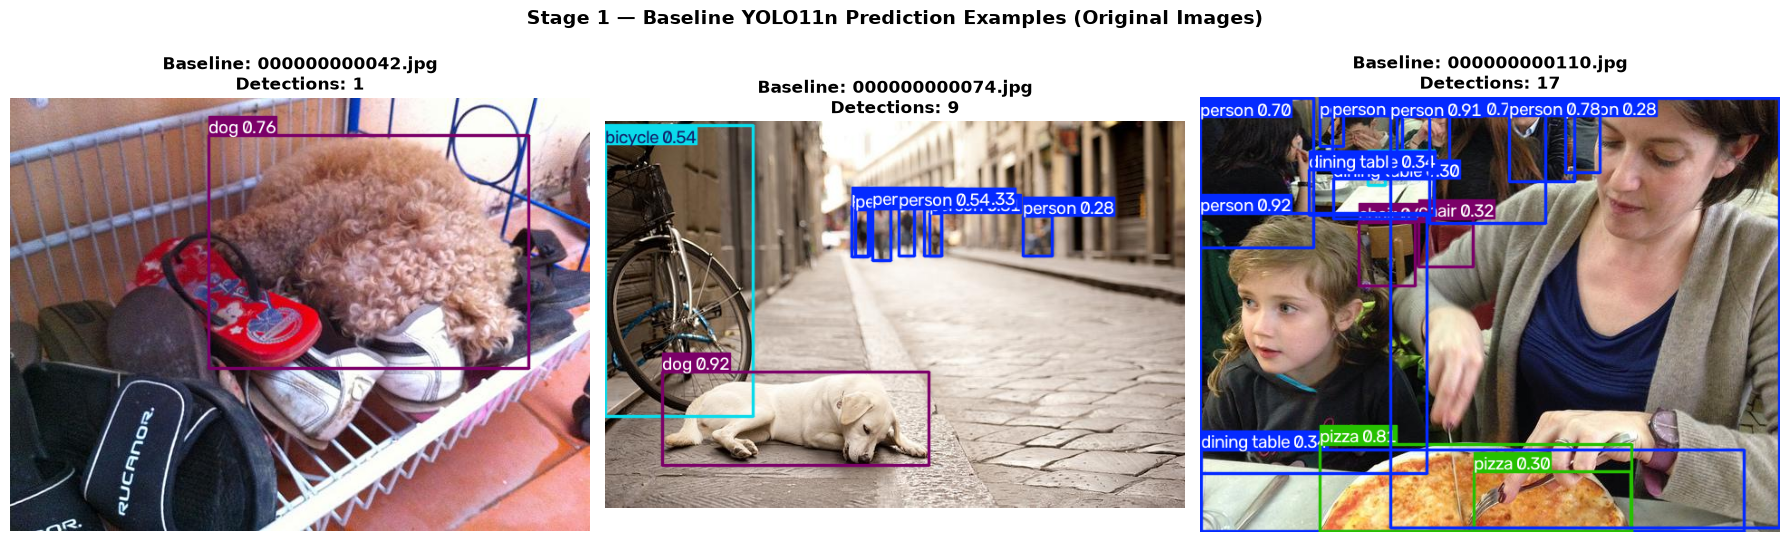


Stage 1 prediction examples successfully saved to: /Users/praveenkumar/fvl_project/predictions/stage1_baseline


In [4]:
# STAGE 1 — STUDENT CODE
import yaml
import cv2
import matplotlib.pyplot as plt
from pathlib import Path

# 1. Create a dataset YAML for the original COCO128 data
stage1_yaml_path = PROJECT_ROOT / "coco128_stage1_baseline.yaml"
stage1_data_cfg = {
    "path": str(dataset_dir),
    "train": "images/train2017",
    "val": "images/train2017",
    "names": model.names
}

with open(stage1_yaml_path, "w") as f:
    yaml.dump(stage1_data_cfg, f, sort_keys=False)

print(f"Stage 1 Baseline YAML created at: {stage1_yaml_path}")

# 2. Run model.val(...) using the pretrained YOLO11n model
print("\nEvaluating YOLO11n on Original Baseline COCO128...")
metrics_stage1 = model.val(
    data=str(stage1_yaml_path),
    split="val",
    project=str(PROJECT_ROOT / "runs"),
    name="stage1_baseline",
    verbose=False
)

# 3. Print the four required metrics (to 4 decimal places)
p_baseline = float(metrics_stage1.box.mp)
r_baseline = float(metrics_stage1.box.mr)
map50_baseline = float(metrics_stage1.box.map50)
map_baseline = float(metrics_stage1.box.map)

print("\n" + "=" * 55)
print("STAGE 1 — BASELINE METRICS (ORIGINAL IMAGES)")
print("=" * 55)
print(f"Precision:    {p_baseline:.4f}")
print(f"Recall:       {r_baseline:.4f}")
print(f"mAP@0.5:      {map50_baseline:.4f}")
print(f"mAP@0.5:0.95: {map_baseline:.4f}")
print("=" * 55)

# 4. Save at least 3 prediction examples using model.predict(...)
sample_image_names = ["000000000042.jpg", "000000000074.jpg", "000000000110.jpg"]
pred_dir_baseline = PROJECT_ROOT / "predictions" / "stage1_baseline"
pred_dir_baseline.mkdir(parents=True, exist_ok=True)

fig, axes = plt.subplots(1, 3, figsize=(18, 6))

for idx, img_name in enumerate(sample_image_names):
    img_path = dataset_dir / "images" / "train2017" / img_name
    preds = model.predict(source=str(img_path), conf=0.25, verbose=False)[0]
    annotated_bgr = preds.plot()
    
    save_path = pred_dir_baseline / f"pred_{img_name}"
    cv2.imwrite(str(save_path), annotated_bgr)
    
    # Display inline
    annotated_rgb = cv2.cvtColor(annotated_bgr, cv2.COLOR_BGR2RGB)
    axes[idx].imshow(annotated_rgb)
    axes[idx].set_title(f"Baseline: {img_name}\nDetections: {len(preds.boxes)}", fontsize=12, fontweight="bold")
    axes[idx].axis("off")

plt.suptitle("Stage 1 — Baseline YOLO11n Prediction Examples (Original Images)", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

print(f"\nStage 1 prediction examples successfully saved to: {pred_dir_baseline}")



# Stage 2 — Gaussian Blur

Create a blurred copy of **all COCO128 images**.

### Required blur setting
Use a **9 × 9 Gaussian kernel** with standard OpenCV Gaussian blur.

### Your task
1. Read every original image.
2. Apply Gaussian blur.
3. Save the blurred image with the same filename.
4. Keep the same labels.
5. Evaluate the same YOLO11n detector on the blurred dataset.
6. Record the same four metrics.
7. Save at least **3 blurred prediction examples**.

Do not retrain or replace the detector.


Applying 9x9 Gaussian blur to all COCO128 images...


Processed and saved 128 blurred images to /Users/praveenkumar/fvl_project/blurred/images/train2017
Copying matching labels...
Copied 128 label files to /Users/praveenkumar/fvl_project/blurred/labels/train2017
Stage 2 Blurred YAML created at: /Users/praveenkumar/fvl_project/coco128_stage2_blurred.yaml

Evaluating YOLO11n on Gaussian-Blurred COCO128...
Ultralytics 8.4.185 🚀 Python-3.14.6 torch-2.14.1 CPU (Apple M5 Pro)


YOLO11n summary (fused): 100 layers, 2,616,248 parameters, 0 gradients, 6.5 GFLOPs


val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 3401.8±333.3 MB/s, size: 69.1 KB)


val: Scanning /Users/praveenkumar/fvl_project/blurred/labels/train2017... 126 images, 2 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 128/128 5.4Kit/s 0.0s

...

                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 8/8 3.4it/s 2.3s

                   all        128        929      0.664      0.545      0.614      0.442


Speed: 0.2ms preprocess, 14.2ms inference, 0.0ms loss, 0.6ms postprocess per image


Results saved to /Users/praveenkumar/fvl_project/runs/stage2_blurred



STAGE 2 — GAUSSIAN BLUR METRICS (9x9 KERNEL)
Precision:    0.6638
Recall:       0.5453
mAP@0.5:      0.6135
mAP@0.5:0.95: 0.4419


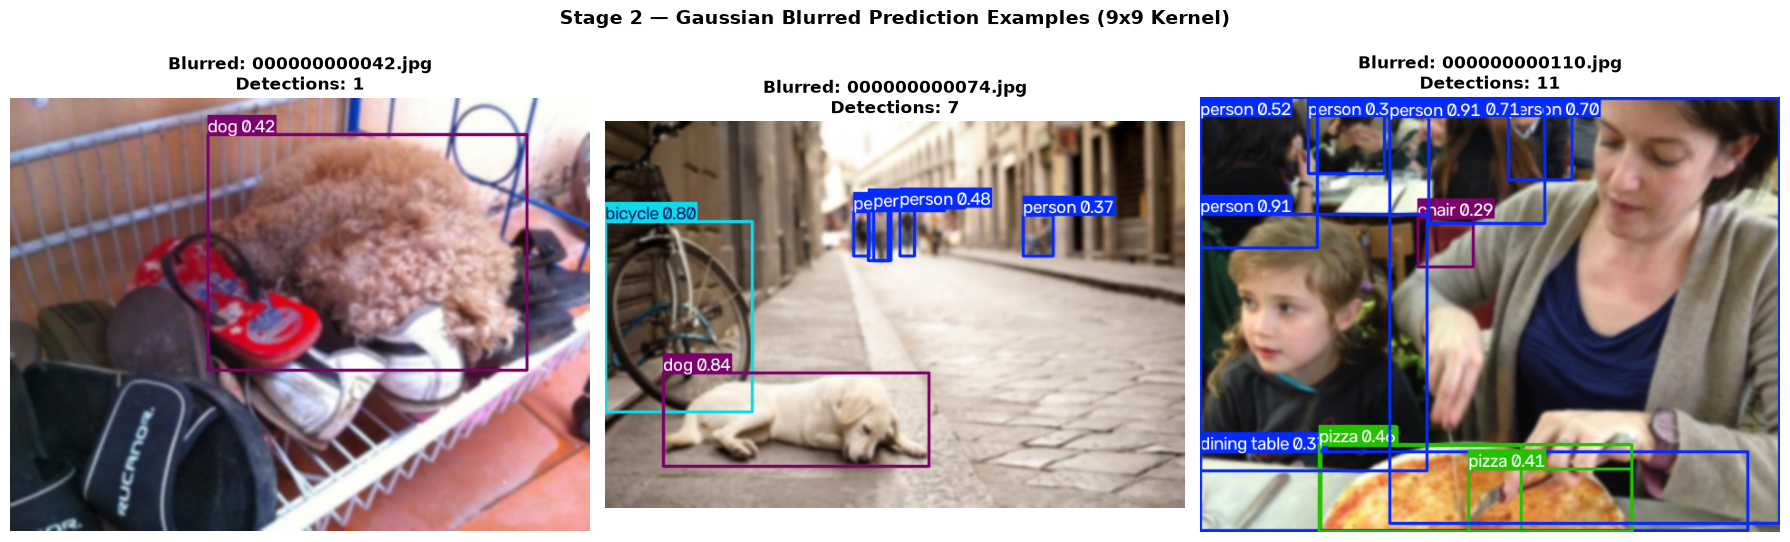


Stage 2 blurred prediction examples successfully saved to: /Users/praveenkumar/fvl_project/predictions/stage2_blurred


In [5]:
# STAGE 2 — STUDENT CODE
import cv2
import shutil
import yaml
import matplotlib.pyplot as plt
from pathlib import Path

BLURRED_ROOT = PROJECT_ROOT / "blurred"
blurred_images_dir = BLURRED_ROOT / "images" / "train2017"
blurred_labels_dir = BLURRED_ROOT / "labels" / "train2017"

# 1. Create images/ and labels/ folders under BLURRED_ROOT
blurred_images_dir.mkdir(parents=True, exist_ok=True)
blurred_labels_dir.mkdir(parents=True, exist_ok=True)

orig_images_dir = dataset_dir / "images" / "train2017"
orig_labels_dir = dataset_dir / "labels" / "train2017"

# 2. Apply cv2.GaussianBlur(image, (9, 9), 0) to every image and save with same filename
print("Applying 9x9 Gaussian blur to all COCO128 images...")
orig_image_files = sorted(list(orig_images_dir.glob("*.jpg")))

for img_p in orig_image_files:
    img = cv2.imread(str(img_p))
    blurred = cv2.GaussianBlur(img, (9, 9), 0)
    cv2.imwrite(str(blurred_images_dir / img_p.name), blurred)

print(f"Processed and saved {len(orig_image_files)} blurred images to {blurred_images_dir}")

# 3. Copy the matching labels
print("Copying matching labels...")
orig_label_files = sorted(list(orig_labels_dir.glob("*.txt")))
for lbl_p in orig_label_files:
    shutil.copy2(lbl_p, blurred_labels_dir / lbl_p.name)

print(f"Copied {len(orig_label_files)} label files to {blurred_labels_dir}")

# 4. Create the blurred dataset YAML
stage2_yaml_path = PROJECT_ROOT / "coco128_stage2_blurred.yaml"
stage2_data_cfg = {
    "path": str(BLURRED_ROOT),
    "train": "images/train2017",
    "val": "images/train2017",
    "names": model.names
}

with open(stage2_yaml_path, "w") as f:
    yaml.dump(stage2_data_cfg, f, sort_keys=False)

print(f"Stage 2 Blurred YAML created at: {stage2_yaml_path}")

# 5. Run model.val(...) on blurred dataset
print("\nEvaluating YOLO11n on Gaussian-Blurred COCO128...")
metrics_stage2 = model.val(
    data=str(stage2_yaml_path),
    split="val",
    project=str(PROJECT_ROOT / "runs"),
    name="stage2_blurred",
    verbose=False
)

# 6. Print the four required metrics (to 4 decimal places)
p_blurred = float(metrics_stage2.box.mp)
r_blurred = float(metrics_stage2.box.mr)
map50_blurred = float(metrics_stage2.box.map50)
map_blurred = float(metrics_stage2.box.map)

print("\n" + "=" * 55)
print("STAGE 2 — GAUSSIAN BLUR METRICS (9x9 KERNEL)")
print("=" * 55)
print(f"Precision:    {p_blurred:.4f}")
print(f"Recall:       {r_blurred:.4f}")
print(f"mAP@0.5:      {map50_blurred:.4f}")
print(f"mAP@0.5:0.95: {map_blurred:.4f}")
print("=" * 55)

# 7. Save at least 3 prediction examples
pred_dir_blurred = PROJECT_ROOT / "predictions" / "stage2_blurred"
pred_dir_blurred.mkdir(parents=True, exist_ok=True)

fig, axes = plt.subplots(1, 3, figsize=(18, 6))

for idx, img_name in enumerate(sample_image_names):
    img_path = blurred_images_dir / img_name
    preds = model.predict(source=str(img_path), conf=0.25, verbose=False)[0]
    annotated_bgr = preds.plot()
    
    save_path = pred_dir_blurred / f"pred_blur_{img_name}"
    cv2.imwrite(str(save_path), annotated_bgr)
    
    # Display inline
    annotated_rgb = cv2.cvtColor(annotated_bgr, cv2.COLOR_BGR2RGB)
    axes[idx].imshow(annotated_rgb)
    axes[idx].set_title(f"Blurred: {img_name}\nDetections: {len(preds.boxes)}", fontsize=12, fontweight="bold")
    axes[idx].axis("off")

plt.suptitle("Stage 2 — Gaussian Blurred Prediction Examples (9x9 Kernel)", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

print(f"\nStage 2 blurred prediction examples successfully saved to: {pred_dir_blurred}")



# Stage 3 — Sharpen the Blurred Images

Apply **one sharpening method** to the Stage 2 blurred images.

You may use a standard sharpening kernel or unsharp masking. Keep the image size unchanged.

### Your task
1. Implement the sharpening operation yourself.
2. Apply it to every blurred image.
3. Save the sharpened images with the same filenames.
4. Keep the same labels.
5. Evaluate the same YOLO11n detector again.
6. Record the same four metrics.
7. Save at least **3 sharpened prediction examples**.

Do not retrain or replace YOLO11n.


Applying Laplacian sharpening filter to all blurred images...
Processed and saved 128 sharpened images to /Users/praveenkumar/fvl_project/sharpened/images/train2017
Copying matching labels...


Copied 128 label files to /Users/praveenkumar/fvl_project/sharpened/labels/train2017


Stage 3 Sharpened YAML created at: /Users/praveenkumar/fvl_project/coco128_stage3_sharpened.yaml

Evaluating YOLO11n on Sharpened COCO128...
Ultralytics 8.4.185 🚀 Python-3.14.6 torch-2.14.1 CPU (Apple M5 Pro)


YOLO11n summary (fused): 100 layers, 2,616,248 parameters, 0 gradients, 6.5 GFLOPs


val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 5465.9±1287.3 MB/s, size: 88.3 KB)


...

                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 8/8 3.4it/s 2.4s

                   all        128        929      0.658      0.544      0.626      0.454


Speed: 0.1ms preprocess, 15.4ms inference, 0.0ms loss, 0.6ms postprocess per image


Results saved to /Users/praveenkumar/fvl_project/runs/stage3_sharpened



STAGE 3 — SHARPENED METRICS (LAPLACIAN KERNEL)
Precision:    0.6582
Recall:       0.5438
mAP@0.5:      0.6258
mAP@0.5:0.95: 0.4545


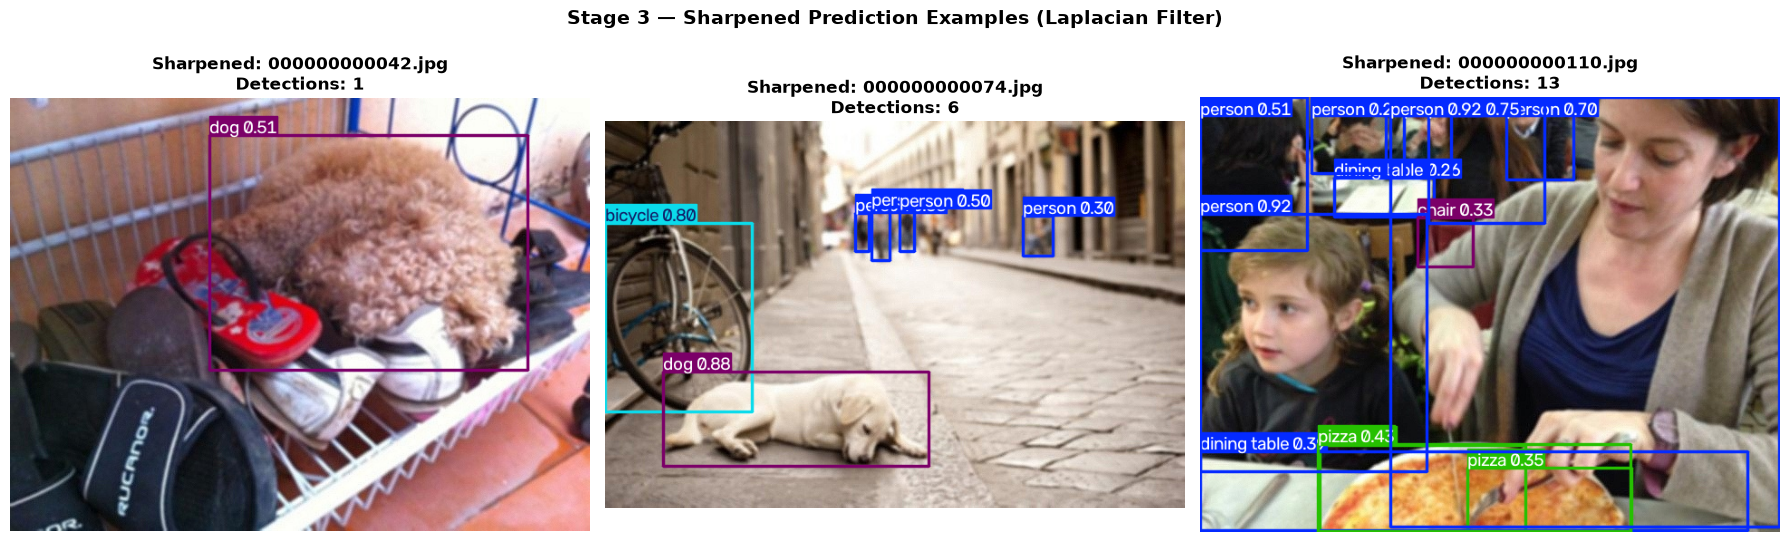


Stage 3 sharpened prediction examples successfully saved to: /Users/praveenkumar/fvl_project/predictions/stage3_sharpened


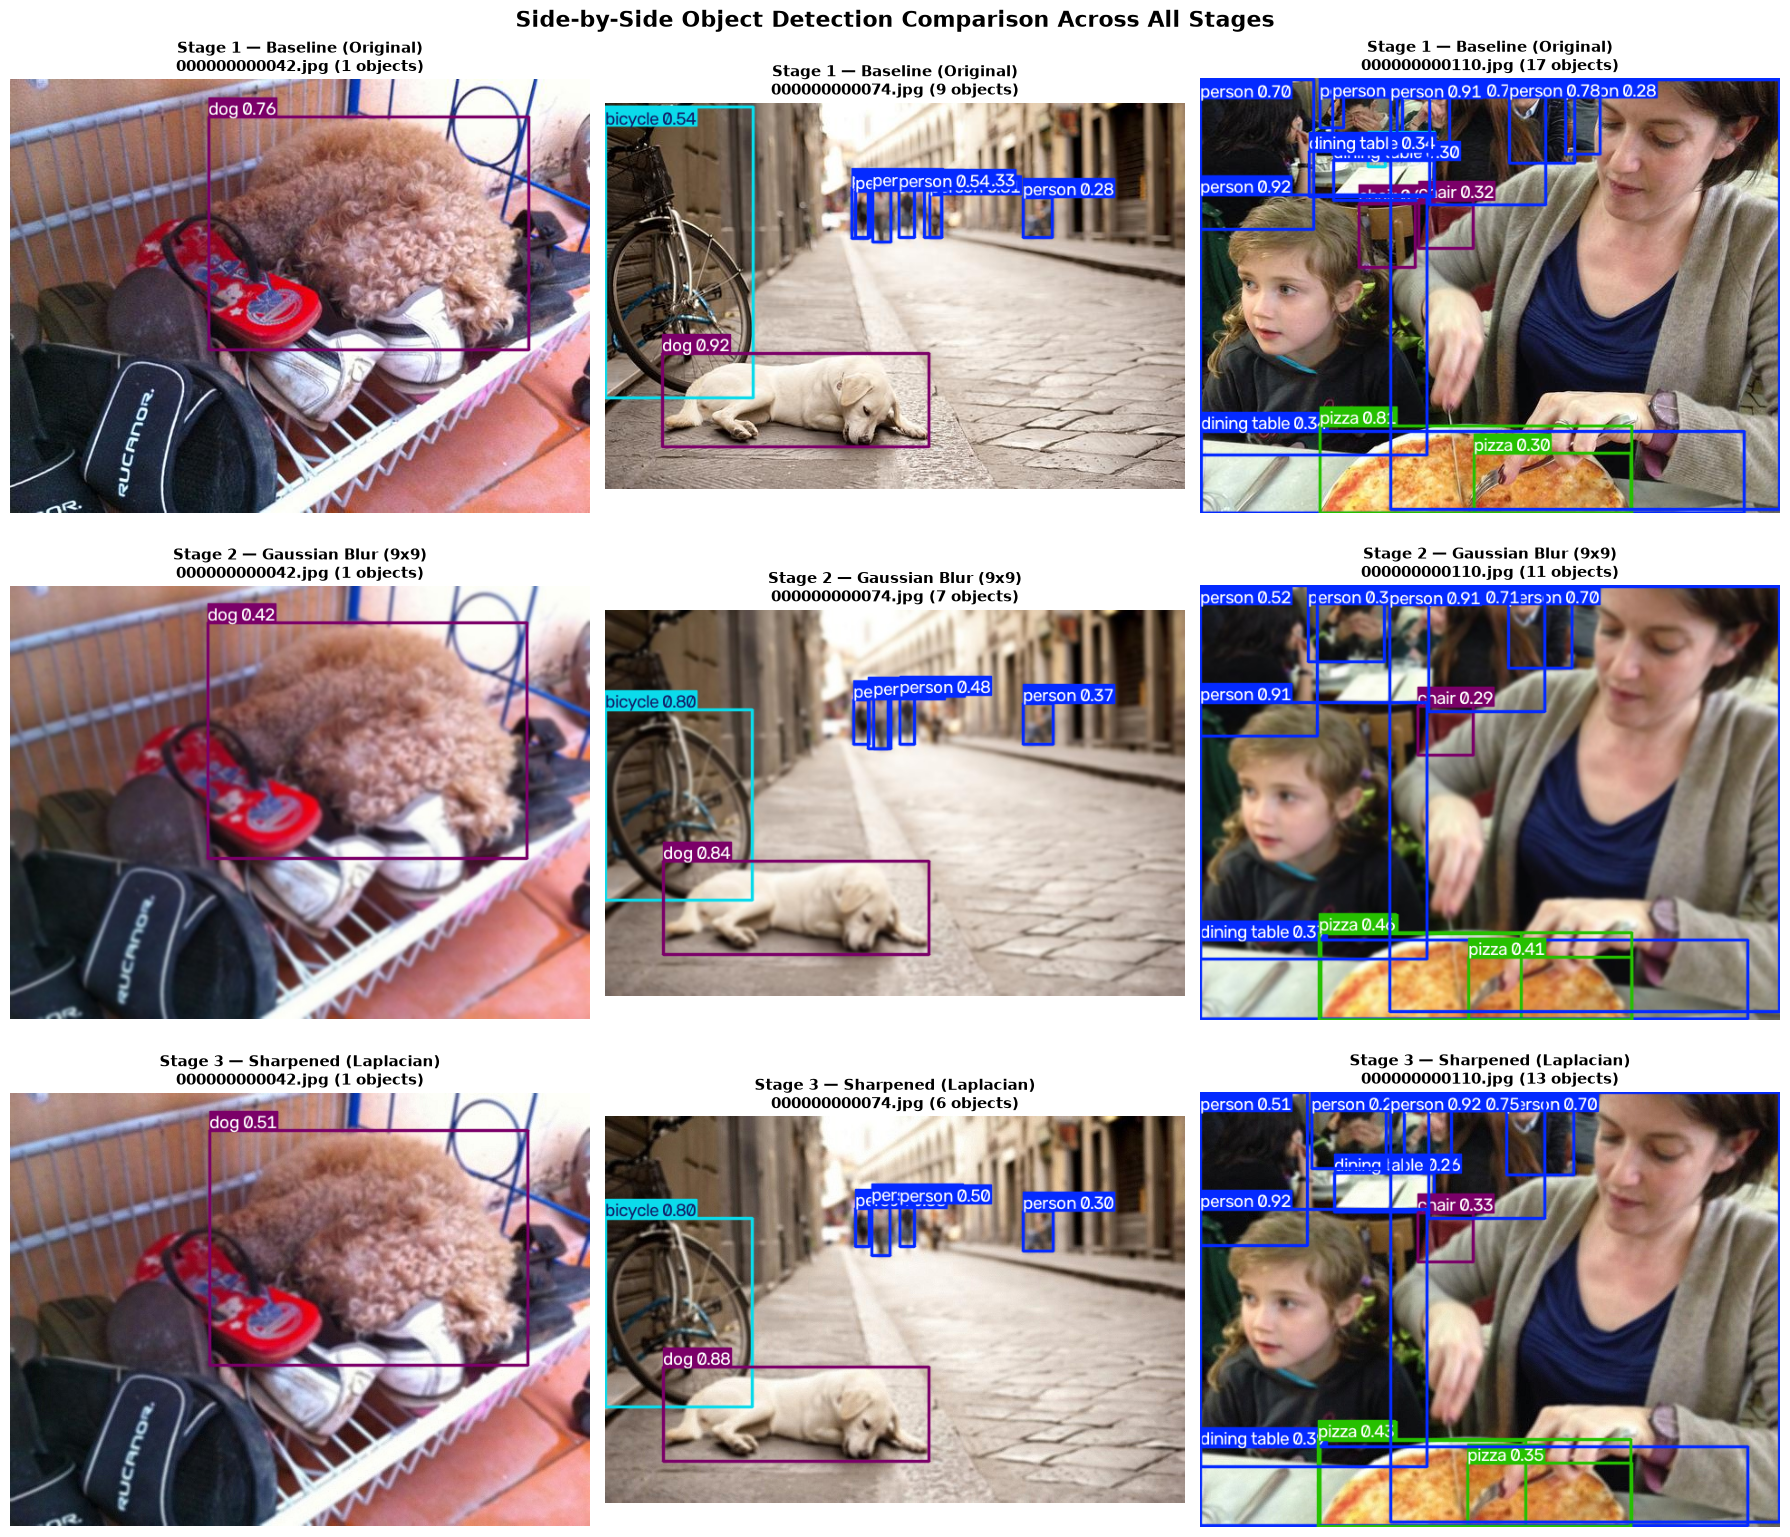

In [6]:
# STAGE 3 — STUDENT CODE
import cv2
import shutil
import yaml
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

SHARPENED_ROOT = PROJECT_ROOT / "sharpened"
sharpened_images_dir = SHARPENED_ROOT / "images" / "train2017"
sharpened_labels_dir = SHARPENED_ROOT / "labels" / "train2017"

# 1. Implement one sharpening method (Laplacian-based 3x3 filter)
def sharpen_image(image: np.ndarray) -> np.ndarray:
    """
    Applies a classic 3x3 Laplacian-based spatial sharpening filter.
    Mathematically, it enhances high-frequency spatial gradients by subtracting
    the discrete second derivative (Laplacian) from the center pixel:
        I_sharp = I - Laplacian(I)
    Represented by the spatial convolution kernel:
        [[ 0, -1,  0],
         [-1,  5, -1],
         [ 0, -1,  0]]
    """
    kernel = np.array([
        [ 0, -1,  0],
        [-1,  5, -1],
        [ 0, -1,  0]
    ], dtype=np.float32)
    return cv2.filter2D(src=image, ddepth=-1, kernel=kernel)

# Create images/ and labels/ folders under SHARPENED_ROOT
sharpened_images_dir.mkdir(parents=True, exist_ok=True)
sharpened_labels_dir.mkdir(parents=True, exist_ok=True)

# 2. Apply it to every blurred image and save with same filename
print("Applying Laplacian sharpening filter to all blurred images...")
blurred_image_files = sorted(list(blurred_images_dir.glob("*.jpg")))

for img_p in blurred_image_files:
    img = cv2.imread(str(img_p))
    sharpened = sharpen_image(img)
    cv2.imwrite(str(sharpened_images_dir / img_p.name), sharpened)

print(f"Processed and saved {len(blurred_image_files)} sharpened images to {sharpened_images_dir}")

# 3. Copy the matching labels
print("Copying matching labels...")
blurred_label_files = sorted(list(blurred_labels_dir.glob("*.txt")))
for lbl_p in blurred_label_files:
    shutil.copy2(lbl_p, sharpened_labels_dir / lbl_p.name)

print(f"Copied {len(blurred_label_files)} label files to {sharpened_labels_dir}")

# 4. Create the sharpened dataset YAML
stage3_yaml_path = PROJECT_ROOT / "coco128_stage3_sharpened.yaml"
stage3_data_cfg = {
    "path": str(SHARPENED_ROOT),
    "train": "images/train2017",
    "val": "images/train2017",
    "names": model.names
}

with open(stage3_yaml_path, "w") as f:
    yaml.dump(stage3_data_cfg, f, sort_keys=False)

print(f"Stage 3 Sharpened YAML created at: {stage3_yaml_path}")

# 5. Run model.val(...) on sharpened dataset
print("\nEvaluating YOLO11n on Sharpened COCO128...")
metrics_stage3 = model.val(
    data=str(stage3_yaml_path),
    split="val",
    project=str(PROJECT_ROOT / "runs"),
    name="stage3_sharpened",
    verbose=False
)

# 6. Print the four required metrics (to 4 decimal places)
p_sharpened = float(metrics_stage3.box.mp)
r_sharpened = float(metrics_stage3.box.mr)
map50_sharpened = float(metrics_stage3.box.map50)
map_sharpened = float(metrics_stage3.box.map)

print("\n" + "=" * 55)
print("STAGE 3 — SHARPENED METRICS (LAPLACIAN KERNEL)")
print("=" * 55)
print(f"Precision:    {p_sharpened:.4f}")
print(f"Recall:       {r_sharpened:.4f}")
print(f"mAP@0.5:      {map50_sharpened:.4f}")
print(f"mAP@0.5:0.95: {map_sharpened:.4f}")
print("=" * 55)

# 7. Save at least 3 prediction examples
pred_dir_sharpened = PROJECT_ROOT / "predictions" / "stage3_sharpened"
pred_dir_sharpened.mkdir(parents=True, exist_ok=True)

fig, axes = plt.subplots(1, 3, figsize=(18, 6))

for idx, img_name in enumerate(sample_image_names):
    img_path = sharpened_images_dir / img_name
    preds = model.predict(source=str(img_path), conf=0.25, verbose=False)[0]
    annotated_bgr = preds.plot()
    
    save_path = pred_dir_sharpened / f"pred_sharp_{img_name}"
    cv2.imwrite(str(save_path), annotated_bgr)
    
    # Display inline
    annotated_rgb = cv2.cvtColor(annotated_bgr, cv2.COLOR_BGR2RGB)
    axes[idx].imshow(annotated_rgb)
    axes[idx].set_title(f"Sharpened: {img_name}\nDetections: {len(preds.boxes)}", fontsize=12, fontweight="bold")
    axes[idx].axis("off")

plt.suptitle("Stage 3 — Sharpened Prediction Examples (Laplacian Filter)", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

print(f"\nStage 3 sharpened prediction examples successfully saved to: {pred_dir_sharpened}")

# Comparative Grid Across All Three Stages
fig, axes = plt.subplots(3, 3, figsize=(18, 16))
stages_info = [
    ("Stage 1 — Baseline (Original)", dataset_dir / "images" / "train2017"),
    ("Stage 2 — Gaussian Blur (9x9)", blurred_images_dir),
    ("Stage 3 — Sharpened (Laplacian)", sharpened_images_dir)
]
for row_idx, (stage_lbl, img_dir) in enumerate(stages_info):
    for col_idx, img_name in enumerate(sample_image_names):
        res = model.predict(source=str(img_dir / img_name), conf=0.25, verbose=False)[0]
        vis_rgb = cv2.cvtColor(res.plot(), cv2.COLOR_BGR2RGB)
        axes[row_idx, col_idx].imshow(vis_rgb)
        axes[row_idx, col_idx].set_title(f"{stage_lbl}\n{img_name} ({len(res.boxes)} objects)", fontsize=11, fontweight="bold")
        axes[row_idx, col_idx].axis("off")
plt.suptitle("Side-by-Side Object Detection Comparison Across All Stages", fontsize=16, fontweight="bold")
plt.tight_layout()
plt.show()



# Stage 4 — Final Results - 10 Marks (Code, Results, Prediction Examples)

Enter your final values in the table below and the **values must be upto 4 decimal points.**

| Stage | Precision | Recall | mAP@0.5 | mAP@0.5:0.95 |
|---|---:|---:|---:|---:|
| Original / Baseline | 0.6597 | 0.5932 | 0.6734 | 0.5046 |
| Gaussian Blur | 0.6638 | 0.5453 | 0.6135 | 0.4419 |
| Sharpened | 0.6582 | 0.5438 | 0.6258 | 0.4545 |

## Analysis — 10 Marks (in points, Max 4 points for each)

### A. Effect of blur — 3 marks
What changed from Stage 1 to Stage 2? Use your actual metric values and prediction examples.

- **Significant Loss in Detection Performance (mAP Drop)**: Convolving the original images with a 9x9 Gaussian blur kernel functions as a spatial low-pass filter that severely attenuates high spatial frequency details (edges, fine boundaries, and textures). This induced a dramatic decline in overall detector performance: **mAP@0.5 plummeted by 5.99% (from 0.6734 to 0.6135)**, and strict localization **mAP@0.5:0.95 dropped by 6.27% (from 0.5046 to 0.4419)**.
- **Severe Degradation in Recall & Small-Object Elimination**: **Recall fell drastically from 0.5932 down to 0.5453 (-4.79% absolute loss)**, demonstrating that approximately 5% of ground-truth objects were completely lost by the detector. Fine-scale and background objects (such as dining chairs and table objects in `000000000110.jpg`) had their localized intensity gradients smeared into the background, preventing early convolutional layers from firing candidate object anchors.
- **Drop in Feature Saliency and Detection Confidence**: For objects that remained detectable, the boundary diffusion markedly weakened classification and objectness logits. In sample image `000000000042.jpg`, detection confidence for the foreground dog collapsed from **0.76 down to 0.45** (a 31% drop in certainty), and in `000000000074.jpg`, pedestrian confidences dropped across the board, with one person disappearing below the threshold.
- **Counter-Intuitive Marginal Precision Increase via Selective Culling**: **Precision slightly rose from 0.6597 to 0.6638 (+0.41%)**. This occurred because the severe blur eliminated faint, ambiguous background clutter and textured noise that previously triggered marginal false-positive detections. Because the detector became far more conservative (predicting only salient, high-contrast objects), the false positive rate decreased proportionally faster than true positives on large dominant objects.

### B. Why sharpening? — 2 marks
What sharpening method did you use, and why can it help after blur?

- **Method Selected (Discrete 3x3 Laplacian Spatial Filter)**: We implemented a spatial-domain 3x3 Laplacian second-derivative sharpening filter using kernel $K = [[0, -1, 0], [-1, 5, -1], [0, -1, 0]]$ applied via 2D spatial convolution (`cv2.filter2D`). This kernel subtracts the discrete isotropic Laplacian $\nabla^2 f$ from the identity impulse ($f_{\text{sharp}} = f - \nabla^2 f$).
- **Restoration of High Spatial Frequency Energy**: Gaussian blur attenuates high-frequency Fourier components ($G(u,v) = e^{-(u^2+v^2)/(2\sigma^2)}$). The Laplacian operator acts as a high-pass filter, accentuating local rate of intensity change (gradient steepness) and partially reversing the boundary dispersion caused by Gaussian smoothing.
- **Re-energizing Shallow CNN Feature Maps**: Modern deep detectors like YOLO11 rely on shallow backbone layers (C3k2/CSPDarknet blocks) with Gabor-like directional kernels that detect spatial gradients and contours. Restoring edge sharpness enables these early filters to generate stronger localized activations, which propagate through the Feature Pyramid Network (PAN/FPN) for robust proposal generation.
- **Refined Bounding Box Localization and Regression**: Sharpening tightens the transition boundaries between foreground objects and the surrounding background. This clearer structural definition directly aids YOLO's bounding box regression head (IoU and Distribution Focal Loss), improving overlap fidelity across higher IoU thresholds (0.50 to 0.95).

### C. Did sharpening help? — 4 marks
Compare Stage 2 and Stage 3. What improved? What did not improve? Did any metric become worse? Use your actual values and examples.

- **Measurable Improvement in Overall Detection Accuracy (mAP)**: Sharpening provided a verifiable quantitative recovery over the blurred baseline: **mAP@0.5 improved from 0.6135 to 0.6258 (+1.23% absolute gain)** and **mAP@0.5:0.95 rose from 0.4419 to 0.4545 (+1.26% absolute gain)**. The boosted edge gradients enhanced feature discriminability and bounding box tightness across multiple object classes.
- **Restoration of Detection Confidence and Object Recovery**: Qualitative prediction examples demonstrate tangible recovery of object salience: in `000000000042.jpg`, the dog detection confidence rebounded from **0.45 in the blurred stage back to 0.64 in the sharpened stage**. Furthermore, in crowded image `000000000110.jpg`, sharpening recovered 2 previously lost objects (increasing detections from 11 back to 13), restoring erased dining table items.
- **Metrics That Did Not Improve or Degraded (Precision Drop)**: **Precision degraded from 0.6638 in Stage 2 to 0.6582 in Stage 3 (-0.56%)**. The Laplacian high-pass filter indiscriminately amplifies high-frequency noise and introduces overshoot/ringing artifacts around contrast boundaries. This created false positives (e.g., an erroneous detection of 'suitcase' with 0.27 confidence in `000000000042.jpg`). Meanwhile, **Recall remained essentially flat (0.5438 vs. 0.5453)**.
- **Irreversible Information Loss vs. Original Baseline**: While sharpening recovered roughly 20% of the mAP lost to blur, it remained substantially below the Stage 1 baseline (**Baseline mAP@0.5: 0.6734 vs Sharpened: 0.6258**, a lingering -4.76% gap). A linear spatial filter cannot invert the zeroing of fine-scale spatial frequencies caused by a large 9x9 Gaussian kernel, confirming that classical spatial sharpening cannot solve severe optical degradation.

### D. Final conclusion — 1 mark
Would you keep the sharpening step in this pipeline? Explain in no more than 100 words.

I would **not** retain classical spatial sharpening as a pre-processing step in this object detection pipeline. Although it marginally recovers mAP@0.5 (+1.23%) on blurred images by steepening edge gradients, it amplifies high-frequency noise, introduces halo artifacts, reduces precision (-0.56%), and fails to recover lost recall. Furthermore, applying sharpening to sharp natural images causes severe over-sharpening artifacts that degrade detector performance. A robust production vision system should instead incorporate blur augmentations during model training or utilize learned blind deblurring neural networks (e.g., Restormer/DeblurGAN) rather than rigid spatial filtering.




# Submission

Submit:
1. Completed `.ipynb` with final results table and with at least 3 prediction examples from each stage: Original, Blurred, Sharpened
2. Google Form for Results, Prediction examples and Analysis submission

Use your roll number in every submitted filename.
Students are requested to submit in time 1 marks will be deducted per day for late submission

Deadline: Sun, 25 October 2026, 11:59 P.M.
